# Ratio Spread

A ratio spread is when options are not bought in a one-to-one ratio. For example, a trader can believe movements in one direction are more likely than movements in another. As with other volatility spreads, the spread is typically delta neutral (?). 


## Delta-neutral 1:3 call ratio spread

With the underlying at **100**, sell one call at strike **95** and buy three calls at a higher strike, all with the same expiry.

Use 90 days to expiry, annual volatility of 20%, and zero interest and dividends. Choose the long strike numerically so that the combined delta is zero **at underlying price 100 when the trade is entered**:

$$-\Delta_C(100,95) + 3\Delta_C(100,K_{\mathrm{long}})=0.$$

Each purchased call must therefore have one third of the sold call's delta. The resulting long strike is above 100. Delta neutrality is local: it does not persist at other underlying prices or as time passes. A ratio spread is not automatically delta neutral.

The three panels show the sold call, the three purchased calls, and their sum. Each panel compares theoretical value with 90 days remaining (solid) against payoff at expiry (dashed), excluding entry premiums. The horizontal axis varies the underlying price while keeping the option strikes fixed. The contracts expire 90 days after entry; delta neutrality is calculated at entry, not at expiry.

Sell 1 call at strike 95.00: delta -0.714350
Buy 3 calls at strike 107.861654: delta per call 0.238117
Net delta at underlying 100: -0.0000000000
Initial signed position value: -2.8925
Initial premium received: 2.8925


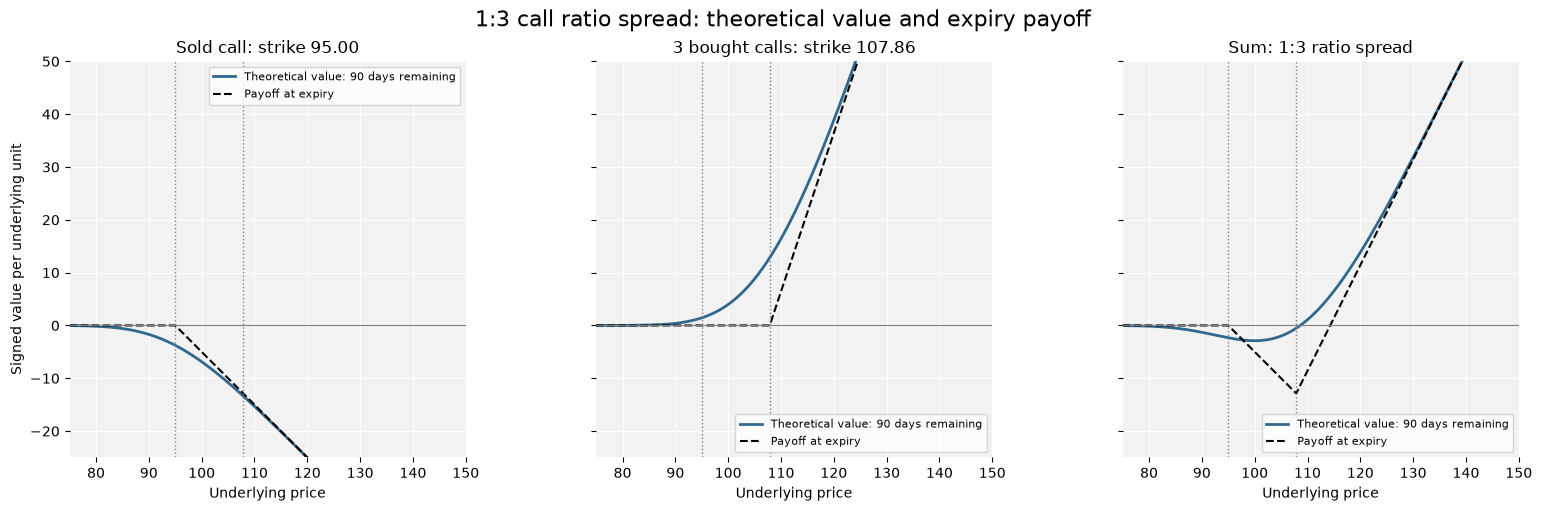

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import brentq

from straddles import Call

initial_spot = 100
short_strike = 95
volatility = 0.20
rate = 0.0
dividend = 0.0
expiry_days = 90
tau = expiry_days / 365
spot = np.linspace(initial_spot - 25, initial_spot + 50, 1501)
theo_color = "#31688e"  # 90 days remaining

short_call = Call(short_strike, tau, volatility)
short_delta = short_call.delta(initial_spot, rate=rate, dividend=dividend)
long_strike = brentq(
    lambda strike: (
        3
        * Call(strike, tau, volatility).delta(
            initial_spot, rate=rate, dividend=dividend
        )
        - short_delta
    ),
    initial_spot,
    2 * initial_spot,
)
long_call = Call(long_strike, tau, volatility)
ratio_spread = 3 * long_call - short_call
initial_value = ratio_spread.theo(initial_spot, rate=rate, dividend=dividend)
initial_delta = ratio_spread.delta(initial_spot, rate=rate, dividend=dividend)

print(f"Sell 1 call at strike {short_strike:.2f}: delta {-short_delta:.6f}")
print(
    f"Buy 3 calls at strike {long_strike:.6f}: "
    f"delta per call {long_call.delta(initial_spot, rate=rate, dividend=dividend):.6f}"
)
print(f"Net delta at underlying 100: {initial_delta:.10f}")
print(f"Initial signed position value: {initial_value:.4f}")
print(f"Initial premium received: {-initial_value:.4f}")
assert long_strike > initial_spot > short_strike
assert abs(initial_delta) < 1e-10

positions = [
    (-short_call, f"Sold call: strike {short_strike:.2f}"),
    (3 * long_call, f"3 bought calls: strike {long_strike:.2f}"),
    (ratio_spread, "Sum: 1:3 ratio spread"),
]
fig, axes = plt.subplots(
    1, 3, figsize=(16, 5), sharex=True, sharey=True, layout="constrained"
)
for ax, (position, title) in zip(axes, positions):
    ax.plot(
        spot,
        position.theo(spot, rate=rate, dividend=dividend),
        color=theo_color,
        linewidth=2,
        label="Theoretical value: 90 days remaining",
    )
    ax.plot(
        spot,
        position.theo(spot, elapsed=tau),
        color="black",
        linestyle="--",
        linewidth=1.5,
        label="Payoff at expiry",
    )
    ax.set(title=title, xlabel="Underlying price")
    ax.set_xlim(initial_spot - 25, initial_spot + 50)
    ax.set_ylim(-25, 50)
    ax.set_aspect("equal", adjustable="box")
    for strike in (short_strike, long_strike):
        ax.axvline(strike, color="grey", linestyle=":", linewidth=1)
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.set_facecolor("#f2f2f2")
    ax.grid(color="white")
    ax.set_axisbelow(True)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.legend(fontsize=8)
axes[0].set_ylabel("Signed value per underlying unit")
fig.suptitle("1:3 call ratio spread: theoretical value and expiry payoff", fontsize=16)
plt.show()

In the final payoff, downside is limited if the asset moves below the lower strike then losses are capped, with potentiall unlimited upside benefit. The opposite position with potential unlimited downside gains can be entered with puts (flip on the x-axis around the strike). The opposite of each postiion can be entered by inverting selling and purchases (flip on the y-axis).

Sell 1 put at strike 105.00: delta 0.670619
Buy 3 puts at strike 93.185755: delta per put -0.223540
Net delta at underlying 100: 0.0000000000
Initial signed position value: -3.0061
Initial premium received: 3.0061


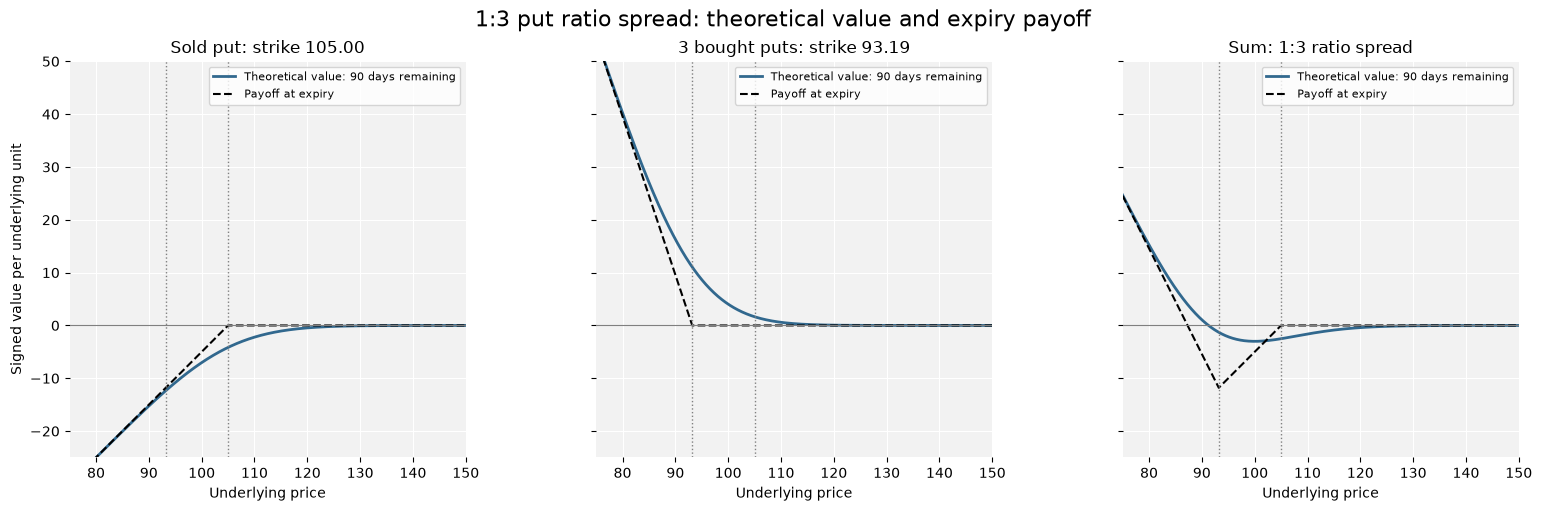

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import brentq

from straddles import Put

initial_spot = 100
short_strike = 105
volatility = 0.20
rate = 0.0
dividend = 0.0
expiry_days = 90
tau = expiry_days / 365
spot = np.linspace(initial_spot - 25, initial_spot + 50, 1501)
theo_color = "#31688e"  # 90 days remaining

short_put = Put(short_strike, tau, volatility)
short_delta = short_put.delta(initial_spot, rate=rate, dividend=dividend)
long_strike = brentq(
    lambda strike: (
        3
        * Put(strike, tau, volatility).delta(initial_spot, rate=rate, dividend=dividend)
        - short_delta
    ),
    0.5 * initial_spot,
    initial_spot,
)
long_put = Put(long_strike, tau, volatility)
ratio_spread = 3 * long_put - short_put
initial_value = ratio_spread.theo(initial_spot, rate=rate, dividend=dividend)
initial_delta = ratio_spread.delta(initial_spot, rate=rate, dividend=dividend)

print(f"Sell 1 put at strike {short_strike:.2f}: delta {-short_delta:.6f}")
print(
    f"Buy 3 puts at strike {long_strike:.6f}: "
    f"delta per put {long_put.delta(initial_spot, rate=rate, dividend=dividend):.6f}"
)
print(f"Net delta at underlying 100: {initial_delta:.10f}")
print(f"Initial signed position value: {initial_value:.4f}")
print(f"Initial premium received: {-initial_value:.4f}")
assert long_strike < initial_spot < short_strike
assert abs(initial_delta) < 1e-10

positions = [
    (-short_put, f"Sold put: strike {short_strike:.2f}"),
    (3 * long_put, f"3 bought puts: strike {long_strike:.2f}"),
    (ratio_spread, "Sum: 1:3 ratio spread"),
]
fig, axes = plt.subplots(
    1, 3, figsize=(16, 5), sharex=True, sharey=True, layout="constrained"
)
for ax, (position, title) in zip(axes, positions):
    ax.plot(
        spot,
        position.theo(spot, rate=rate, dividend=dividend),
        color=theo_color,
        linewidth=2,
        label="Theoretical value: 90 days remaining",
    )
    ax.plot(
        spot,
        position.theo(spot, elapsed=tau),
        color="black",
        linestyle="--",
        linewidth=1.5,
        label="Payoff at expiry",
    )
    ax.set(title=title, xlabel="Underlying price")
    ax.set_xlim(initial_spot - 25, initial_spot + 50)
    ax.set_ylim(-25, 50)
    ax.set_aspect("equal", adjustable="box")
    for strike in (short_strike, long_strike):
        ax.axvline(strike, color="grey", linestyle=":", linewidth=1)
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.set_facecolor("#f2f2f2")
    ax.grid(color="white")
    ax.set_axisbelow(True)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.legend(fontsize=8)
axes[0].set_ylabel("Signed value per underlying unit")
fig.suptitle("1:3 put ratio spread: theoretical value and expiry payoff", fontsize=16)
plt.show()

## Calendar Spreads

Calendar spreads consist of options which expire at different expire types, options of the same type (put or call) are bought and sold at the same time with different expiry times. As theta is greater for options closer to expiry, this enables constructing postions which are long vega while being short theta.

If a long-term option is purchased and a short-term option is sold then the position is long calendar spread. This is because the long-term option is generally worth more as it has increased extrinsic value, and so entering the positon constitutes a debit (as does going long, purchasing, a stock.) Because options at the money have a delta of approximately 50 this is delta neutral, and so calendar spreads are typically entered with ATM options.

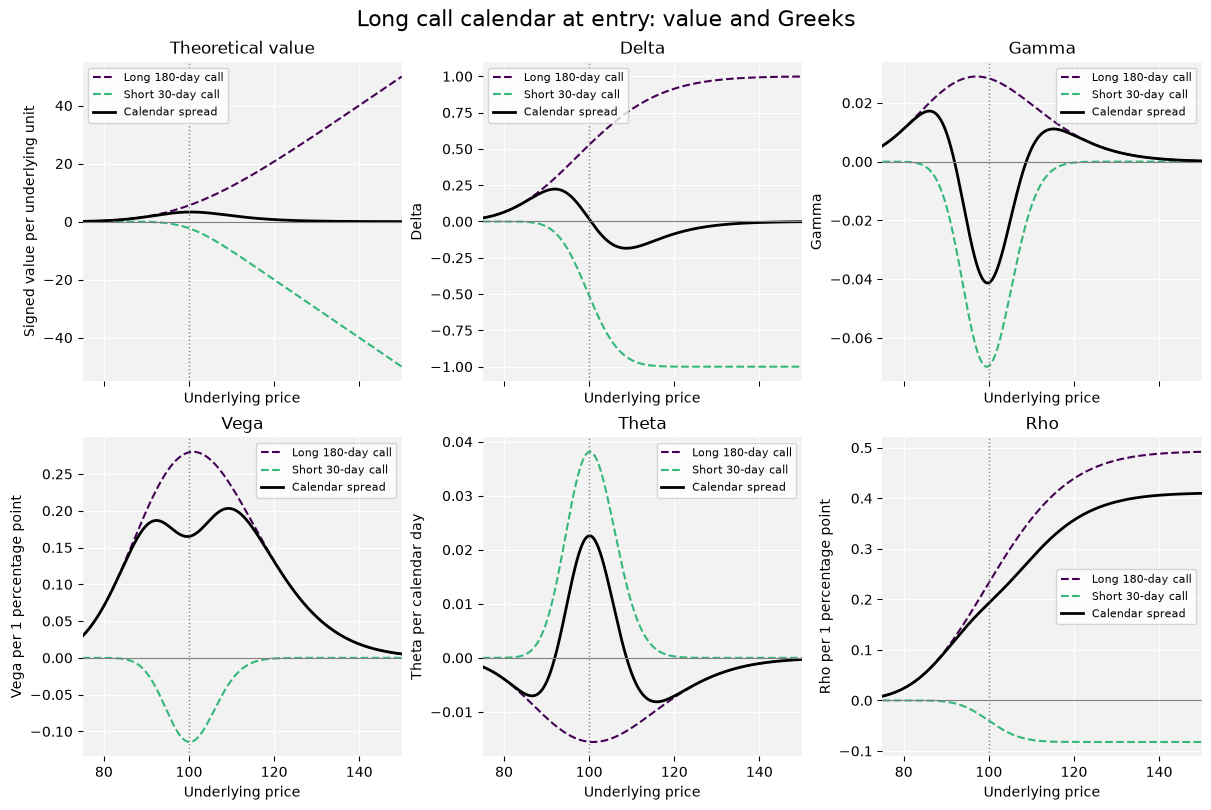

Entry debit at underlying 100: 3.3114
Delta at underlying 100: 0.016557
Gamma at underlying 100: -0.041214
Vega at underlying 100: 0.165140
Theta at underlying 100: 0.022583
Rho at underlying 100: 0.192615


In [3]:
import matplotlib.pyplot as plt
import numpy as np

from straddles import Call

calendar_strike = 100
long_days = 180
short_days = 30
calendar_volatility = 0.20
calendar_spot = np.linspace(75, 150, 1501)
calendar_rate = 0.0
calendar_dividend = 0.0

long_term_call = Call(calendar_strike, long_days / 365, calendar_volatility)
short_term_call = -Call(calendar_strike, short_days / 365, calendar_volatility)
calendar_spread = long_term_call + short_term_call
calendar_positions = [
    (long_term_call, "Long 180-day call", "#440154", "--"),
    (short_term_call, "Short 30-day call", "#35b779", "--"),
    (calendar_spread, "Calendar spread", "black", "-"),
]
calendar_metrics = [
    ("theo", "Theoretical value", "Signed value per underlying unit", 1),
    ("delta", "Delta", "Delta", 1),
    ("gamma", "Gamma", "Gamma", 1),
    ("vega", "Vega", "Vega per 1 percentage point", 100),
    ("theta", "Theta", "Theta per calendar day", 365),
    ("rho", "Rho", "Rho per 1 percentage point", 100),
]

fig, axes = plt.subplots(2, 3, figsize=(12, 8), sharex=True, layout="constrained")
for position, label, color, linestyle in calendar_positions:
    values = position.evaluate(
        calendar_spot, rate=calendar_rate, dividend=calendar_dividend
    )
    for ax, (metric, title, ylabel, scale) in zip(axes.flat, calendar_metrics):
        ax.plot(
            calendar_spot,
            values[metric] / scale,
            color=color,
            linestyle=linestyle,
            linewidth=2 if label == "Calendar spread" else 1.5,
            label=label,
        )

for ax, (_, title, ylabel, _) in zip(axes.flat, calendar_metrics):
    ax.set(title=title, xlabel="Underlying price", ylabel=ylabel, xlim=(75, 150))
    ax.set_box_aspect(1)
    ax.axvline(calendar_strike, color="grey", linestyle=":", linewidth=1)
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.set_facecolor("#f2f2f2")
    ax.grid(color="white")
    ax.set_axisbelow(True)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.legend(fontsize=8)
fig.suptitle("Long call calendar at entry: value and Greeks", fontsize=16)
plt.show()

at_strike = calendar_spread.evaluate(
    calendar_strike, rate=calendar_rate, dividend=calendar_dividend
)
print(f"Entry debit at underlying 100: {at_strike['theo']:.4f}")
for metric, title, _, scale in calendar_metrics[1:]:
    print(f"{title} at underlying 100: {at_strike[metric] / scale:.6f}")

Traditionally, being long an option yields the following:
- Positive vega exposure, an increase in implied volatility increases the value of an option.
- Positive gamma exposure, thinking of delta as the probability of an option being in the money, increasing the underlying increases the delta.
- Negative theta exposure, an option loses extrinsic value over time.

These graphs tell us a few things:
- Positive vega exposure, the long-term call benefits more from increases in volatility than the sold short-term call as there is more time for the volatility to realise.
- Negative gamma exposure, gamma is greater closer to expiry, so the short-term option gamma is greater.* (This does not hold if the underlying moves far away from the strike as the gamma of the short term goes to zero and the term gamma dominates).
- Positive theta exposure, the short-term option decays faster than the long-term option.

A calendar spread will increase in value if time passes without movement in the underlying (positive theta ATM). 

It feels contractory for an option to be long vega (implied volatility) but short gamma (price movements), however this frequently happens if changes are expected with immediate effect. For example there is an earnings call at a company without clear indication what the move will be. The implied volatility will increase expecting price movements without any price movements realised in the underlying. Another example is a 50/50 of interest rates. A trader can enter bull/bearish calendar spreads for a position on the direction of movements by entering a ratio calendar spread.

A quiet market or increase in implied volatility will increase the value of a calendar spread. An active market or decreased implied volatility will decrease the value of a calendar spread.

## Choosing an appropriate strategy

With so many option spreads avaliable to choose from, how does a trader decide which positions to enter? This is the general position: If we believe the market is underpricing volatility, enter positions which have positive vega. If implied volatility is too high, enter positions with negative vega. Long calendar spreads are likely to be profitable when implied volatility is low but is expected to rise; short calendar spreads are likely to be profitable when implied volatility is high but expected to fall. 

## A note on delta hedging

Remaining delta neutral requires continuous delta hedging, in reality this is not possible. Furthermore, as delta is a function of implied volatility, it is unclear what the delta of a position truly is at any given point in time. Traders are generally happy to run a little directional risk.

There are generally four strategies to delta hedging:
1. Adjust at regular intervals: In practice, volatility is measured at regular intervals and delta should be recomputed at those intervals too. 
2. Adjust when the delta becomes too great: Very few traders insist on being delta neutral all the time, it is unrealistic. The decision of this value of delta depends on the firm, for a single trader 500 deltas might be too great a risk. For a large firm 1000 delta might be approximately delta neutral.
3. Adjust by feel: If a trader has built an intuition of the market, and is often right more than not, they should take advantage of this skill.
4. Don't adjust: By extension of the above, sometimes a trader will feel the cost of neutralising deltas is not justified by the cost of entering those positions. With illiquid underlyings, hedging deltas can actually reduce implied volatility and lower the value of the entire position.